In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

ModuleNotFoundError: No module named 'numpy'

In [32]:
df = pd.read_csv("WELFake_Dataset.csv")

In [33]:
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [34]:
df.columns
df.shape


(72134, 4)

In [35]:
df.isnull().sum()

Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

In [37]:
df["title"] = df["title"].fillna("unknown")
df = df.dropna(subset=["text"])

In [38]:
df.isnull().sum()

Unnamed: 0    0
title         0
text          0
label         0
dtype: int64

In [40]:
df["text"].duplicated().sum()

np.int64(9377)

In [41]:
df = df.drop_duplicates(subset=["text"])

In [42]:
df.shape

(62718, 4)

In [43]:
df["text"].duplicated().sum()

np.int64(0)

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 62718 entries, 0 to 72132
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  62718 non-null  int64 
 1   title       62718 non-null  object
 2   text        62718 non-null  object
 3   label       62718 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.4+ MB


In [45]:
df["label"].value_counts()

label
0    34620
1    28098
Name: count, dtype: int64

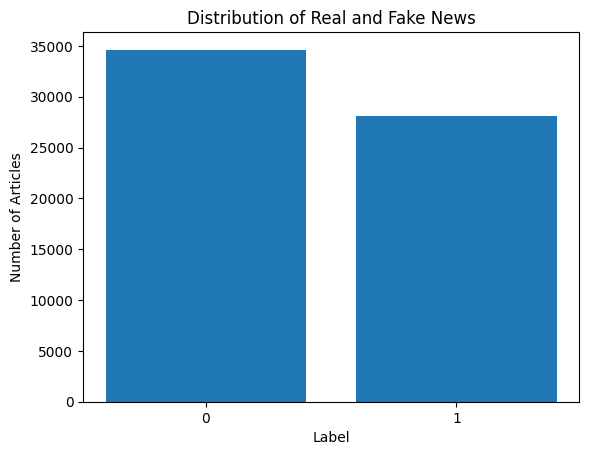

In [46]:
label_counts = df["label"].value_counts()

plt.bar(
    label_counts.index.astype(str),
    label_counts.values
)

plt.xlabel("Label")
plt.ylabel("Number of Articles")
plt.title("Distribution of Real and Fake News")

plt.show()

In [48]:
df["word_count"] = df["text"].apply(
    lambda x: len(str(x).split())
)
df[["text", "word_count"]].head()

C:\Users\hp\AppData\Local\Temp\ipykernel_16240\871175902.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["word_count"] = df["text"].apply(


,text,word_count
0,No comment is expected from Barack Obama Membe...,871
1,Did they post their votes for Hillary already?,8
2,"Now, most of the demonstrators gathered last ...",34
3,A dozen politically active pastors came here f...,1321
4,"The RS-28 Sarmat missile, dubbed Satan 2, will...",329


In [49]:
df["word_count"].describe()

count    62718.000000
mean       548.983625
std        610.055913
min          0.000000
25%        244.000000
50%        406.000000
75%        679.000000
max      24234.000000
Name: word_count, dtype: float64

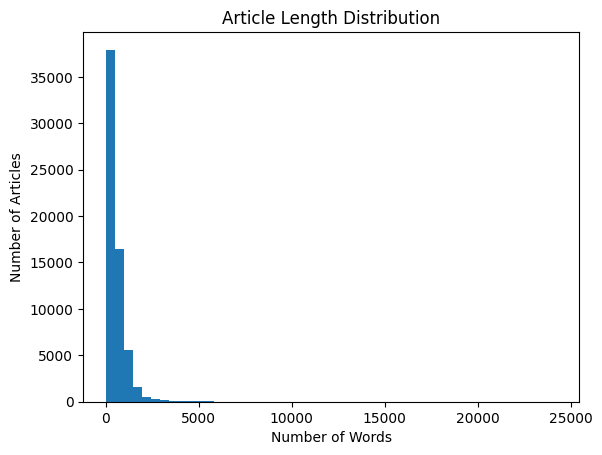

In [50]:
plt.hist(
    df["word_count"],
    bins=50
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.title("Article Length Distribution")

plt.show()

In [51]:
import re
def clean_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    text = re.sub(
        r"<.*?>",
        " ",
        text
    )

    text = re.sub(
        r"[^a-zA-Z\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    text = text.strip()

    return text

In [52]:
sample = "BREAKING!!! Government announced NEW policy @ 10AM."

clean_text(sample)

'breaking government announced new policy am'

In [54]:
df["clean_text"] = df["text"].apply(clean_text)

C:\Users\hp\AppData\Local\Temp\ipykernel_16240\300469187.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["clean_text"] = df["text"].apply(clean_text)


In [26]:
df[["full_text", "clean_text"]].head()

,full_text,clean_text
0,This article provides detailed analysis based ...,this article provides detailed analysis based ...
600,This shocking revelation will completely chang...,this shocking revelation will completely chang...


In [55]:
df = df[
    df["clean_text"].str.strip() != ""
]

In [56]:
df = df.reset_index(drop=True)

In [57]:
X = df["clean_text"]
X

0        no comment is expected from barack obama membe...
1            did they post their votes for hillary already
2        now most of the demonstrators gathered last ni...
3        a dozen politically active pastors came here f...
4        the rs sarmat missile dubbed satan will replac...
                               ...                        
62613    an email released by wikileaks on sunday appea...
62614    washington reuters hackers believed to be work...
62615    you know because in fantasyland republicans ne...
62616    migrants refuse to leave train at refugee camp...
62617    mexico city reuters donald trump s combative s...
Name: clean_text, Length: 62618, dtype: object

In [58]:
y = df["label"]
y

0        1
1        1
2        1
3        0
4        1
        ..
62613    1
62614    0
62615    1
62616    0
62617    0
Name: label, Length: 62618, dtype: int64

In [59]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [60]:
print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 50094
Testing: 12524


In [61]:
from sklearn.feature_extraction.text import CountVectorizer
bow = CountVectorizer(
    max_features=5000,
    stop_words="english"
)

In [62]:
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

In [63]:
print(X_train_bow.shape)
print(X_test_bow.shape)

(50094, 5000)
(12524, 5000)


In [64]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

In [65]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(50094, 5000)
(12524, 5000)


# first ML model logistic regression

In [66]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr.fit(
    X_train_tfidf,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [67]:
lr_pred = lr.predict(
    X_test_tfidf
)

In [68]:
from sklearn.metrics import accuracy_score
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

print("Accuracy:", lr_accuracy)

Accuracy: 0.9350047908016608


In [69]:
from sklearn.metrics import classification_report
print(
    classification_report(
        y_test,
        lr_pred
    )
)

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      6924
           1       0.92      0.93      0.93      5600

    accuracy                           0.94     12524
   macro avg       0.93      0.93      0.93     12524
weighted avg       0.94      0.94      0.94     12524



# KNN model

In [70]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(
    n_neighbors=5
)
knn.fit(
    X_train_tfidf,
    y_train
)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [71]:
knn_pred = knn.predict(
    X_test_tfidf
)

In [72]:
knn_accuracy = accuracy_score(
    y_test,
    knn_pred
)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.6413286489939316


In [73]:
print(
    classification_report(
        y_test,
        knn_pred
    )
)

              precision    recall  f1-score   support

           0       0.89      0.40      0.55      6924
           1       0.56      0.94      0.70      5600

    accuracy                           0.64     12524
   macro avg       0.72      0.67      0.63     12524
weighted avg       0.74      0.64      0.62     12524



# Random forest

In [74]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf.fit(
    X_train_tfidf,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [75]:
rf_pred = rf.predict(
    X_test_tfidf
)
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.9221494730118173


In [76]:
print(
    classification_report(
        y_test,
        rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      0.94      0.93      6924
           1       0.92      0.90      0.91      5600

    accuracy                           0.92     12524
   macro avg       0.92      0.92      0.92     12524
weighted avg       0.92      0.92      0.92     12524



# neural network

In [77]:
from sklearn.neural_network import MLPClassifier
nn = MLPClassifier(
    hidden_layer_sizes=(50,),
    max_iter=100,
    random_state=42
)

In [78]:
nn.fit(
    X_train_tfidf,
    y_train
)

c:\Users\hp\OneDrive\Documents\project 1\venv\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


,hidden_layer_sizes,"(50,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,100
,shuffle,True
,random_state,42


In [79]:
nn_pred = nn.predict(
    X_test_tfidf
)

In [80]:
nn_accuracy = accuracy_score(
    y_test,
    nn_pred
)

print(
    "Neural Network Accuracy:",
    nn_accuracy
)

print(
    classification_report(
        y_test,
        nn_pred
    )
)

Neural Network Accuracy: 0.9266208878952411
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      6924
           1       0.92      0.91      0.92      5600

    accuracy                           0.93     12524
   macro avg       0.93      0.93      0.93     12524
weighted avg       0.93      0.93      0.93     12524



In [81]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest",
        "Neural Network"
    ],

    "Accuracy": [
        lr_accuracy,
        knn_accuracy,
        rf_accuracy,
        nn_accuracy
    ]
})

In [150]:
results

,Model,Accuracy
0,Logistic Regression,0.935005
1,KNN,0.641329
2,Random Forest,0.922149
3,Neural Network,0.926621


In [82]:
results = results.sort_values(
    by="Accuracy",
    ascending=False
)

results

,Model,Accuracy
0,Logistic Regression,0.935005
3,Neural Network,0.926621
2,Random Forest,0.922149
1,KNN,0.641329


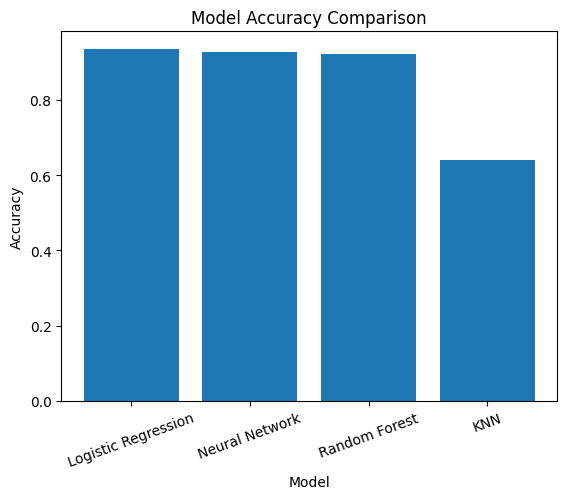

In [83]:
plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=20)

plt.show()

# Model deploymnet 

In [84]:
best_model = lr
import joblib
joblib.dump(
    best_model,
    "fake_news_model.pkl"
)

['fake_news_model.pkl']

In [85]:
joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

['tfidf_vectorizer.pkl']

In [86]:
model = joblib.load(
    "fake_news_model.pkl"
)

vectorizer = joblib.load(
    "tfidf_vectorizer.pkl"
)

In [95]:
def predict_news(news):
    cleaned_news = clean_text(news)
    news_vector = tfidf.transform([cleaned_news])
    prediction = model.predict(news_vector)[0]

    # WELFake dataset:
    # 0 = REAL
    # 1 = FAKE
    if prediction == 0:
        return "REAL"
    else:
        return "FAKE"

In [96]:
news = input(
    "Enter news article: "
)

result = predict_news(news)

print(
    "Prediction:",
    result
)

Prediction: FAKE
